In [28]:
from __future__ import annotations

from pathlib import Path
from glob import glob
from typing import Any, NamedTuple, TypedDict, Callable, Literal, cast

import librosa
import pandas as pd
from numpy.ma.core import indices
from sympy import true

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import numpy as np
from typing import NamedTuple
from functools import partial

tqdm.pandas()

In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset
Audio is preprocessed on another machine, so we need to load them on this machine for training.

In [30]:
prefix = Path("data")

In [31]:
with open(prefix.joinpath("labels.csv"), "r") as f:
    labels: pd.DataFrame = pd.read_csv(f)

Standardise path into prefix/raw/Type/file or prefix/processed/Type/file (discrepancy caused by moving dataset around machine)

In [32]:
labels.source_file = labels.source_file.progress_apply(lambda x: prefix.joinpath(Path("raw", *Path(x).parts[2:])))
labels.processed_file = labels.processed_file.progress_apply(
    lambda x: prefix.joinpath(Path("processed", *Path(x).parts[1:])))

  0%|          | 0/5940 [00:00<?, ?it/s]

  0%|          | 0/5940 [00:00<?, ?it/s]

In [33]:
labels[:3]

,source_file,processed_file,fire_seeker_gain,fire_seeker_low,fire_seeker_mid,fire_seeker_treble
0,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.415212,0.382531,0.889004,0.717846
1,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.828639,0.576327,0.966072,0.016324
2,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.093933,0.267912,0.440884,0.377729


Filter out missing file

In [34]:
def filter_existing(row: pd.Series) -> bool:
    if row.processed_file.exists():
        return True
    else:
        print(f"\033[31mProcessed file {row.processed_file} not found, skipping\033[0m")
        return False

In [35]:
def calc_length(row: pd.Series) -> pd.Series:
    x, sr = librosa.load(row.processed_file)
    row["length"] = len(x)
    return row

In [36]:
tqdm.pandas(desc="Filtering")
filtered = labels[labels.progress_apply(filter_existing, axis=1)]
tqdm.pandas(desc="Calculating sample length")
filtered = filtered.progress_apply(calc_length, axis=1)

Filtering:   0%|          | 0/5940 [00:00<?, ?it/s]

Processed file data/processed/Gretsch/Gretsch_F_open_122_ID1_4_1.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_F_open_122_ID1_4_2.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_F_open_122_ID1_4_3.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_1.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_2.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_3.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_B_open_022_ID1_6_1.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_B_open_022_ID1_6_2.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_B_open_022_ID1_6_3.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_Cm_open_122_ID1_9_1.wav not found, skipping
Processed file data/processed/Gretsch/Gretsch_Cm_open_122_ID1_9_2.wav not found, skipping
Processed fil

Calculating sample length:   0%|          | 0/23 [00:00<?, ?it/s]

## Boilerplates
Scaffolding to share code across different implementations, for the ease of experimenting with various setting, e.g. different features or different models

In [37]:
def to_tensor(x: np.ndarray) -> torch.Tensor:
    return torch.tensor(x, dtype=torch.float)


def extract_X_y(df: pd.DataFrame, *, X_labels: list[str],
                x_mapper: Callable[[pd.DataFrame], np.ndarray] = lambda x: x.to_numpy()) -> \
        tuple[np.ndarray, np.ndarray]:
    return x_mapper(df[X_labels]), naive_features[
        ["fire_seeker_gain", "fire_seeker_low", "fire_seeker_mid"]].to_numpy()


class Dataset[T: torch.Tensor | np.ndarray](TypedDict):
    X_train: T
    y_train: T
    X_val: T
    y_val: T
    X_test: T
    y_test: T


class Collection:
    def __init__(self, model: nn.Module,
                 loss: nn.modules.loss._Loss,
                 optimiser: Callable[[optim.optimizer.ParamsT], torch.optim.Optimizer]):
        self.model = model.to(device)
        self.loss = loss.to(device)
        self.optimiser = optimiser(self.model.parameters())


def to_device(dataset: Dataset[np.ndarray], d=device) -> Dataset[torch.Tensor]:
    return cast(Dataset, dict(
        map(lambda x: (x[0], to_tensor(x[1]).to(d)),
            dataset.items())))


def scale(dataset: Dataset[np.ndarray], scaler) -> Dataset[np.ndarray]:
    return Dataset(X_train=scaler.fit_transform(dataset["X_train"]), y_train=dataset["y_train"],
                   X_val=scaler.transform(dataset["X_val"]), y_val=dataset["y_val"],
                   X_test=scaler.transform(dataset["X_test"]), y_test=dataset["y_test"])


def split_dataset(X: np.ndarray, y: np.ndarray) -> Dataset[np.ndarray]:
    X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, random_state=0)
    X_val_unscaled, X_test_unscaled, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=0)
    return Dataset(X_train=X_train, y_train=y_train, X_val=X_val_unscaled, y_val=y_val, X_test=X_test_unscaled,
                   y_test=y_test)


def test_model(dataset: Dataset, c: Collection,
               sample: int | None = None, key: Literal["test", "val", "train"] = "test"):
    total = torch.tensor(0.0).to(device)
    n = len(dataset["X_" + key])
    tqdm.pandas(desc="Predicting")

    if sample is not None:
        mask = np.zeros(n)
        selected= np.random.choice(n, sample)
        for i in selected:
            mask[i] = 1
    else:
        selected = np.arange(n)
        mask = np.ones(n)

    y_hat = c.model(dataset["X_" + key][mask])
    l = c.loss(y_hat, dataset["y_" + key][mask])

    # slower than just throwing the entire tensor into model and loss, but makes writing the random sampling code easier
    for i in range(l):
        print(f"y: {dataset["y_" + key][selected[i]]} ŷ: {y_hat[i]} loss: {l[i]}")

    avg = total / n
    print(
        f"Average loss{" of entire dataset" if sample is not None else ""}: {avg if sample is None else c.loss(c.model(dataset["X_" + key]), dataset["y_" + key])}")


def train_model(c: Collection, dataset: Dataset[torch.Tensor],
                epochs: int) -> list[float]:
    loss_history = []
    for _ in (n := tqdm(range(epochs), desc="Training")):
        c.optimiser.zero_grad()
        output = c.model(dataset["X_train"])
        loss = c.loss(output, dataset["y_train"])
        loss.backward()
        c.optimiser.step()
        n.postfix = str(loss.item())
        loss_history.append(loss.item())
    return loss_history


def loss_history(hist):
    plt.title("Loss History")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.plot(hist)


## Naive implementation
For our first model, we'll only provide 3 features, root mean square, spectral centroid and zero crossing rate

In [38]:
from feat_ext import root_mean_square, spectral_centroid, zero_crossing_rate


def calculate_naive_features(row: pd.Series) -> pd.Series:
    x, sr = librosa.load(row.processed_file)

    row["root_mean_square"] = root_mean_square(x)
    row["spectral_centroid"] = spectral_centroid(x, sr=sr)
    row["zero_crossing_rate"] = zero_crossing_rate(x)
    return row

In [39]:
tqdm.pandas(desc="Calculating Features")
naive_features = filtered.progress_apply(calculate_naive_features, axis=1)

Calculating Features:   0%|          | 0/23 [00:00<?, ?it/s]

In [40]:
naive_X, naive_y = extract_X_y(naive_features, X_labels=["root_mean_square", "spectral_centroid", "zero_crossing_rate"])
naive_dataset: Dataset = to_device(scale(split_dataset(naive_X, naive_y), StandardScaler()))

We'll be using a basic MLP with only 4 layers (2 hidden) and all activation will be using RELU. Input layer will have our 3 only features, then it widens up to 70 then narrow back down until the output is of size 3 (the 3 parameters we're trying to predict).


In [41]:
class NaiveModel(nn.Module):
    def __init__(self, input_n: int = 3, h1_n: int = 70, h2_n: int = 50, h3_n=20):
        super(NaiveModel, self).__init__()
        self.fc1 = nn.Linear(input_n, h1_n)
        self.fc2 = nn.Linear(h1_n, h2_n)
        self.fc3 = nn.Linear(h2_n, h3_n)
        self.fc4 = nn.Linear(h3_n, 3)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = F.relu(x)

        x = self.fc3(x)
        x = F.relu(x)

        x = self.fc4(x)

        return x

In [42]:
naive = Collection(
    NaiveModel(),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9)
)

naive_loss_history = train_model(naive, naive_dataset, 5000)

Training:   0%|          | 0/5000 [00:00<?, ?it/s]

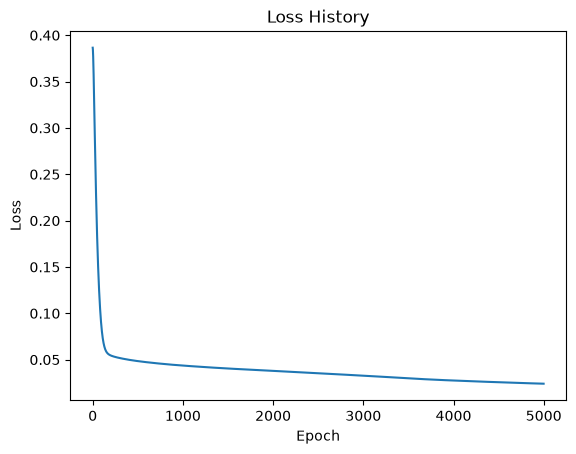

In [43]:
loss_history(naive_loss_history)

In [44]:
test_model(naive_dataset, naive, key="train", sample=3)
test_model(naive_dataset, naive)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.9983, 0.4397, 0.3295], device='cuda:0') ŷ: tensor([1.0165, 0.3823, 0.4220], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.004060264211148024
y: tensor([0.3887, 0.9489, 0.8846], device='cuda:0') ŷ: tensor([0.2337, 0.5692, 0.6142], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.08044306933879852
y: tensor([0.2383, 0.2142, 0.1094], device='cuda:0') ŷ: tensor([0.2984, 0.5245, 0.4261], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.06671471893787384
Average loss of entire dataset: 0.024082113057374954


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.1488, 0.3568, 0.6391], device='cuda:0') ŷ: tensor([0.2874, 0.5818, 0.5216], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.027881136164069176
y: tensor([0.3526, 0.6182, 0.0148], device='cuda:0') ŷ: tensor([0.3933, 0.6369, 0.3955], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.048989176750183105
y: tensor([0.7001, 0.9338, 0.7921], device='cuda:0') ŷ: tensor([0.8061, 0.5959, 0.5103], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.06828033179044724
Average loss: 0.048383548855781555


The naive attempts did not preform well for test dataset (and it definitely did not generalise well). With equally terrible accuracy for both seen and unseen data, this is expected, as we only have 3 features and it is very unlikely to be enough.

## Second attempt
For out second attempts, instead of calculating our features for the entire samples, we take slices of out sample and calculate features on them, hopefully this gives more information that the model need to preform better. Here, I kept the window and frame length as librosa's default.

In [59]:
from librosa.feature import rms, spectral_centroid, zero_crossing_rate


def calculate_windowed_naive_features() -> Callable[[pd.Series], pd.Series]:
    samples = min(filtered["length"]) # truncate out excess, most audio clip should be ~5 second, but with some very small variation that we can just chop out
    def _inner(row: pd.Series) -> pd.Series:
        x, sr = librosa.load(row.processed_file)
        x = x[:samples]
        S = np.abs(librosa.stft(x))
        row["root_mean_square"] = rms(S=S)[0]
        row["spectral_centroid"] = spectral_centroid(y=x, sr=sr)[0]
        row["zero_crossing_rate"] = zero_crossing_rate(x)[0]
        return row

    return _inner

In [60]:
tqdm.pandas(desc="Calculating Features")
windowed_naive_feature = filtered.progress_apply(calculate_windowed_naive_features(), axis=1)

Calculating Features:   0%|          | 0/23 [00:00<?, ?it/s]

(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)
(212,)


Machine learning model expects a flat 1D array as features, so we have to concatenate the three feature column containing ndarry each into a single ndarry.

In [47]:
def flatten(x: pd.DataFrame) -> np.ndarray:
    x = x.apply(
        lambda row: np.concatenate([row["root_mean_square"], row["spectral_centroid"], row["zero_crossing_rate"]],
                                   dtype=np.float32), axis=1)
    return np.vstack(x.to_numpy()).astype(np.float32)

In [48]:
windowed_naive_X, windowed_naive_y = extract_X_y(windowed_naive_feature,
                                                 X_labels=["root_mean_square", "spectral_centroid",
                                                           "zero_crossing_rate"], x_mapper=flatten)
windowed_naive_dataset = to_device(scale(split_dataset(windowed_naive_X, windowed_naive_y), StandardScaler()))

I've decided to use the exact same model as before, but with a larger input layer to accommodate for all the features.

In [49]:
windowed_naive_old_neurons = Collection(
    NaiveModel(input_n=windowed_naive_X.shape[1]),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9)
)

windowed_naive_old_neurons_loss_history = train_model(windowed_naive_old_neurons, windowed_naive_dataset, 1000)

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

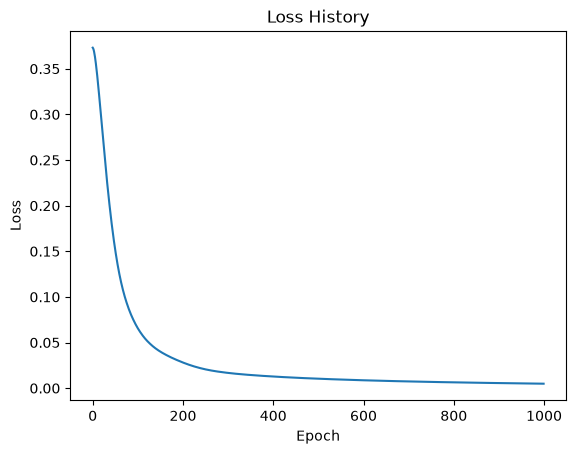

In [50]:
loss_history(windowed_naive_old_neurons_loss_history)

For comparison, I made a model with significantly more neuron on each hidden layer


In [51]:
windowed_naive_larger_model = Collection(
    NaiveModel(input_n=windowed_naive_X.shape[1], h1_n=1000, h2_n=500, h3_n=100),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9)
)

windowed_naive_larger_model_loss_history = train_model(windowed_naive_larger_model, windowed_naive_dataset, 1000)

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

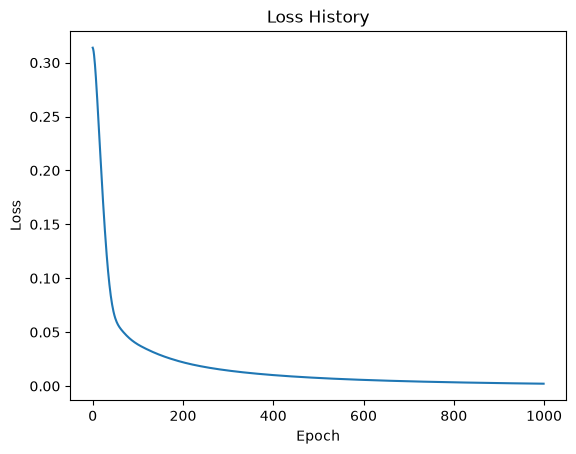

In [52]:
loss_history(windowed_naive_larger_model_loss_history)

In [53]:
test_model(windowed_naive_dataset, windowed_naive_old_neurons, key="train", sample=3)
test_model(windowed_naive_dataset, windowed_naive_old_neurons, key="val")

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.1691, 0.6211, 0.7468], device='cuda:0') ŷ: tensor([0.2449, 0.5683, 0.5633], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.01406565960496664
y: tensor([0.1043, 0.2870, 0.3032], device='cuda:0') ŷ: tensor([0.1809, 0.2515, 0.3831], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.00450210040435195
y: tensor([0.7563, 0.5680, 0.4661], device='cuda:0') ŷ: tensor([0.7522, 0.5629, 0.4675], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 1.4974600162531715e-05
Average loss of entire dataset: 0.004881608299911022


  0%|          | 0/2 [00:00<?, ?it/s]

y: tensor([0.8440, 0.2866, 0.7749], device='cuda:0') ŷ: tensor([0.9428, 0.3832, 0.4007], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.053034257143735886
y: tensor([0.0863, 0.8660, 0.8084], device='cuda:0') ŷ: tensor([0.2007, 0.9025, 0.8455], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.005268225446343422
Average loss: 0.02915124222636223


In [54]:
test_model(windowed_naive_dataset, windowed_naive_larger_model, key="train", sample=3)
test_model(windowed_naive_dataset, windowed_naive_larger_model, key="val")

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.8877, 0.5227, 0.6788], device='cuda:0') ŷ: tensor([0.9012, 0.5157, 0.6815], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 7.95646192273125e-05
y: tensor([0.6770, 0.3948, 0.4812], device='cuda:0') ŷ: tensor([0.5380, 0.4219, 0.4254], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.007722546346485615
y: tensor([0.3984, 0.7224, 0.2890], device='cuda:0') ŷ: tensor([0.4189, 0.7198, 0.3287], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0006657560588791966
Average loss of entire dataset: 0.0021568883676081896


  0%|          | 0/2 [00:00<?, ?it/s]

y: tensor([0.8440, 0.2866, 0.7749], device='cuda:0') ŷ: tensor([0.9174, 0.5077, 0.5886], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.029672926291823387
y: tensor([0.0863, 0.8660, 0.8084], device='cuda:0') ŷ: tensor([0.3266, 0.8095, 0.8160], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.020334627479314804
Average loss: 0.02500377595424652


While both model preformed quite well at the training data, the one with same neurons count as our naive model preforms worse at training data compared to the larger model. On the validation dataset, both preform quite terribly, but the larger model produce slightly smaller loss.

Understandably, now that we slice and sample chunk of the sample, and have more than 3 features, the machine learning model have a lot more information to work with compared to the naive model. This is likely why the new model is so much better at training dataset than naive, but it seems like it did not generalise well, perhaps it simply learned to distinguish between all the audio sample in training dataset.

In [67]:
print(f"{windowed_naive_X.shape[1]} features")
print(f"{windowed_naive_feature.spectral_centroid.iloc[0].shape[0]} value per features")

636 features
212 value per features


And in hindsight, I feel like a total of 636 features was excessive, I probably should've diverted from librosa's default, ~5 features per second and 25 features for an entire clips sound more reasonable.